✅ 成功筛选到充电数据，共 1234 行
✅ 本次充电循环总容量为: 1.4950 Ah


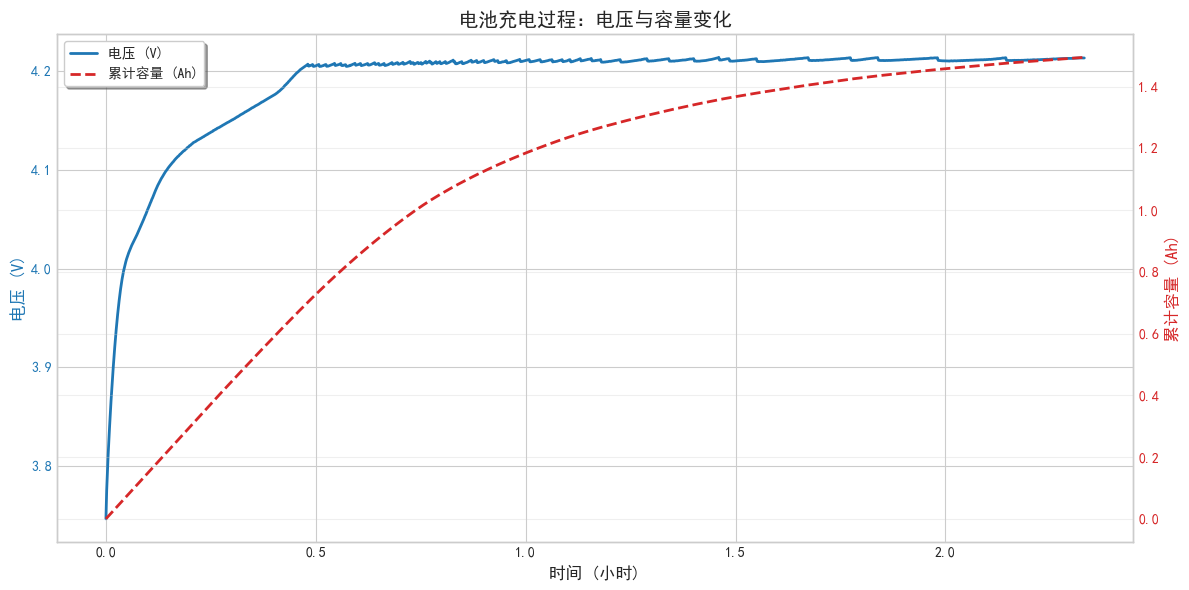

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# ==================== 1. 环境设置 ====================
# 设置清爽的图表风格
plt.style.use('seaborn-v0_8-whitegrid')

# 设置中文字体，防止图表中的中文显示为方块
plt.rcParams['font.sans-serif'] = ['SimHei']  # Windows 用 SimHei，Mac 请改为 ['Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False    # 正常显示负号

# ==================== 2. 读取数据 ====================
# 读取充电数据（请确保文件路径和文件名正确）
file_path = "./data/00003.csv" 
df = pd.read_csv(file_path)

# ==================== 3. 数据预处理与特征工程 ====================
# 将时间从秒转换为小时，方便后续积分计算和图表阅读
df['Time_h'] = df['Time'] / 3600

# 筛选出真正的充电阶段（核心逻辑修改）
# 电池充电时，电流流入电池，Current_measured 为正值。这里设定阈值 > 0.1
df_charge = df[df['Current_measured'] > 0.1].copy()

# ⚠️ 安全检查：防止因为选错文件或阈值设置错误导致后续计算崩溃
if len(df_charge) == 0:
    print("❌ 错误：没有筛选到充电数据！请检查该文件电流是否为正值，或调整阈值。")
else:
    print(f"✅ 成功筛选到充电数据，共 {len(df_charge)} 行")
    
    # 计算时间差（相邻两个采样点的时间间隔，单位为小时）
    df_charge['dt_h'] = df_charge['Time_h'].diff().fillna(0)
    
    # 安时积分：计算每个时间步长内流入的电量 (安培 * 小时 = Ah)
    df_charge['Ah_step'] = abs(df_charge['Current_measured']) * df_charge['dt_h']
    
    # 累计求和，得到每个时间点的总充电容量
    df_charge['Capacity_Ah'] = df_charge['Ah_step'].cumsum()
    
    # 提取最终的总充电容量（本次循环的容量）
    final_capacity = df_charge['Capacity_Ah'].iloc[-1]
    print(f"✅ 本次充电循环总容量为: {final_capacity:.4f} Ah")
    
    # ==================== 4. 绘制双Y轴曲线 ====================
    fig, ax1 = plt.subplots(figsize=(12, 6))

    # --- 左轴：绘制电压曲线（蓝色） ---
    color_voltage = '#1f77b4'
    ax1.plot(df_charge['Time_h'], df_charge['Voltage_measured'], 
             color=color_voltage, linewidth=2, label='电压 (V)')
    ax1.set_xlabel('时间 (小时)', fontsize=12)
    ax1.set_ylabel('电压 (V)', color=color_voltage, fontsize=12)
    ax1.tick_params(axis='y', labelcolor=color_voltage)

    # --- 右轴：绘制累计容量曲线（红色虚线） ---
    ax2 = ax1.twinx()  # 创建共享X轴的第二个Y轴
    color_capacity = '#d62728'
    ax2.plot(df_charge['Time_h'], df_charge['Capacity_Ah'], 
             color=color_capacity, linewidth=2, linestyle='--', label='累计容量 (Ah)')
    ax2.set_ylabel('累计容量 (Ah)', color=color_capacity, fontsize=12)
    ax2.tick_params(axis='y', labelcolor=color_capacity)

    # --- 合并图例并美化 ---
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    # 将图例合并，统一放在左上角（因为充电时曲线一般向右上角延伸，左上角不遮挡）
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=10, frameon=True, shadow=True)

    plt.title('电池充电过程：电压与容量变化', fontsize=14, fontweight='bold')
    plt.grid(True, alpha=0.3)
    fig.tight_layout()
    plt.show()